# M4.1 · 协方差收缩与 RMT 去噪

> 均值-方差优化的质量，本质上取决于协方差矩阵估计的质量。当资产数 n 接近观测数 T 时，样本协方差矩阵病态、估计误差被优化器放大，常得到极端角点解。
> 本节系统对比：样本协方差、Ledoit-Wolf 收缩、随机矩阵理论（RMT）去噪、因子模型协方差，并考察条件数与稳定性。

## 一、样本协方差为什么不可靠

样本协方差 $\hat\Sigma=\frac{1}{T-1}\sum_t (r_t-\bar r)(r_t-\bar r)^\top$ 在高维下有三个问题：

1. **估计误差大**：需估计 $n(n+1)/2$ 个元素，当 $n/T$ 不小时，大量元素是噪声；
2. **病态（ill-conditioned）**：最小特征值被严重低估，条件数 $\lambda_{\max}/\lambda_{\min}$ 很大，求逆放大误差；
3. **优化器利用噪声**：均值-方差优化会「做多」被低估方差、「做空」被高估方差的资产，得到看似最优、实则虚假的角点解。

**两条主流改进路线：**
- **收缩（shrinkage）**：把样本协方差向结构化目标加权收缩，偏差换方差；
- **RMT 去噪**：用随机矩阵理论识别并清洗噪声特征值。


## 二、准备数据：沪深300 前 50 只、近 750 个交易日

In [1]:
import sys
sys.path.insert(0, r'C:\Users\gucao\Desktop\Qlib')
import numpy as np, pandas as pd
import qlib
from qlib.data import D
from l2.config import load_universe
import config
from port_lab2 import covariance as covm
qlib.init(provider_uri=str(config.QLIB_DAILY_DIR), joblib_backend='threading')
codes = load_universe('hs300')
raw = D.features(codes, ['$close'], start_time='2018-01-01', freq='day')
cl = raw['$close'].unstack('instrument')
ret = cl.pct_change(fill_method=None)
sub = ret.iloc[-750:, :50].dropna(axis=1)
print('收益子集:', sub.shape, ' 最新日期:', str(sub.index[-1])[:10])
print('n/T = %.4f' % (sub.shape[1]/sub.shape[0]))

[24748:MainThread](2026-11-05 14:07:30,326) INFO - qlib.Initialization - [config.py:452] - default_conf: client.


[24748:MainThread](2026-11-05 14:07:32,691) INFO - qlib.Initialization - [__init__.py:75] - qlib successfully initialized based on client settings.


[24748:MainThread](2026-11-05 14:07:32,693) INFO - qlib.Initialization - [__init__.py:77] - data_path={'__DEFAULT_FREQ': WindowsPath('C:/Users/gucao/Desktop/Qlib/data/qlib_daily')}


收益子集: (750, 50)  最新日期: 2026-11-02
n/T = 0.0667


## 三、样本协方差与条件数

In [2]:
S = covm.sample_cov(sub)
cond = covm.condition_number(sub)
print('样本协方差形状:', S.shape)
print('条件数 = %.1f（越大越病态，1 表示完全良态）' % cond)
print('年化波动率范围: [%.3f, %.3f]'
      % (np.sqrt(np.diag(S)*242).min(), np.sqrt(np.diag(S)*242).max()))

样本协方差形状: (50, 50)
条件数 = 167.0（越大越病态，1 表示完全良态）
年化波动率范围: [0.191, 0.567]


## 四、Ledoit-Wolf 收缩

Ledoit-Wolf(2004) 在样本协方差 $S$ 与结构化目标 $F$ 之间做凸组合：

$$\Sigma_{\text{shrink}}=(1-\delta)S+\delta F,\qquad F=\frac{\operatorname{tr}(S)}{n}I$$

收缩强度 $\delta$ 由**最小化 Frobenius 期望损失**的闭式解给出，自动在「偏差」与「方差」间权衡。下面分别用自实现与 sklearn 对照。

In [3]:
lw_self, d_self = covm.ledoit_wolf_shrink(sub)
lw_sk, d_sk = covm.ledoit_wolf_sklearn(sub)
print('自实现 收缩强度 delta = %.4f' % d_self)
print('sklearn 收缩强度     = %.4f' % d_sk)
print('两估计 Frobenius 距离 = %.8f' % covm.frob_distance(lw_self, lw_sk))
print('收缩后条件数 = %.1f（样本为 %.1f）'
      % (np.linalg.cond(lw_self.values), cond))

自实现 收缩强度 delta = 0.0350
sklearn 收缩强度     = 0.0350
两估计 Frobenius 距离 = 0.00000000
收缩后条件数 = 115.5（样本为 167.0）


## 五、随机矩阵理论（RMT）去噪

对随机收益矩阵，Marchenko-Pastur 给出纯噪声特征值的理论分布，其边界为：

$$q=\frac{n}{T},\qquad \lambda_{\pm}=(1\pm\sqrt q)^2$$

低于 $\lambda_+$ 的特征值视为噪声。**常数残差特征值法**（Laloux 2000）把这些噪声特征值整体替换为其均值，保留信号特征值，再重建并归一化为相关矩阵。

In [4]:
rm = covm.rmt_denoise(sub)
print('q = %.4f, MP 上界 lambda+ = %.4f' % (rm['q'], rm['lam_plus']))
print('信号特征值个数 = %d, 噪声特征值个数 = %d' % (rm['n_signal'], rm['n_noise']))
print('原始特征值: 最大=%.3f 最小=%.3f' % (rm['eig_raw'].max(), rm['eig_raw'].min()))
print('清洗后噪声特征值统一为 %.4f' % rm['eig_clean'][rm['eig_raw'] < rm['lam_plus']].mean())

q = 0.0667, MP 上界 lambda+ = 1.5831
信号特征值个数 = 5, 噪声特征值个数 = 45
原始特征值: 最大=13.751 最小=0.113
清洗后噪声特征值统一为 0.5679


## 六、因子模型协方差

用单因子（截面等权「市场」收益）建模 $\Sigma=B\Sigma_f B^\top+D$，天然低秩、良态，是 Barra 风险模型的基础。

In [5]:
mkt = sub.mean(axis=1).to_frame('mkt')
fc = covm.factor_model_cov(sub, mkt)
print('因子模型协方差形状:', fc.shape)
print('因子模型条件数 = %.1f' % np.linalg.cond(fc.values))
print('与样本协方差 Frobenius 距离 = %.6f' % covm.frob_distance(fc, S))

因子模型协方差形状: (50, 50)
因子模型条件数 = 67.4
与样本协方差 Frobenius 距离 = 0.002169


## 七、图表对比

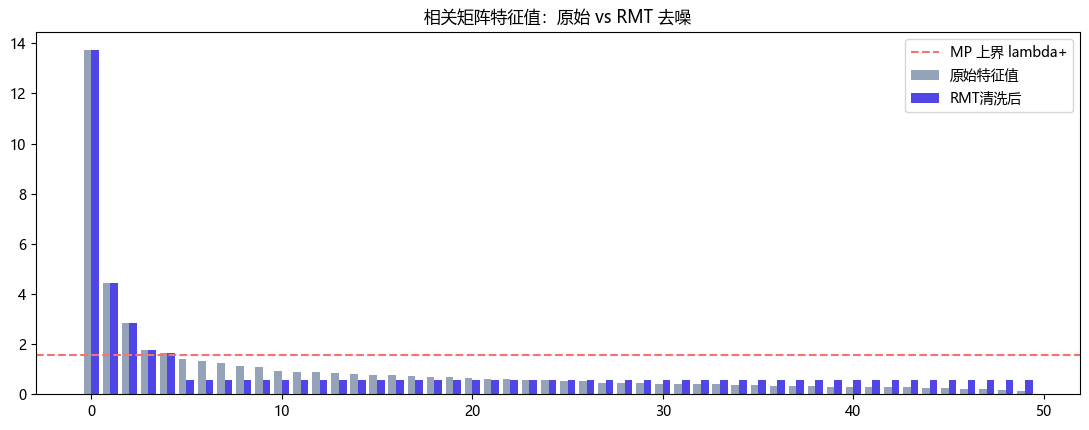

In [6]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
fig, ax = plt.subplots(figsize=(11, 4.4))
idx = np.arange(len(rm['eig_raw']))
ax.bar(idx-0.2, rm['eig_raw'][::-1], 0.4, label='原始特征值', color='#94a3b8')
ax.bar(idx+0.2, rm['eig_clean'][::-1], 0.4, label='RMT清洗后', color='#4f46e5')
ax.axhline(rm['lam_plus'], color='#f87171', ls='--', label='MP 上界 lambda+')
ax.set_title('相关矩阵特征值：原始 vs RMT 去噪'); ax.legend()
plt.tight_layout(); plt.show()

C:\Users\gucao\AppData\Local\Temp\ipykernel_24748\4130775010.py:9: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(); plt.show()


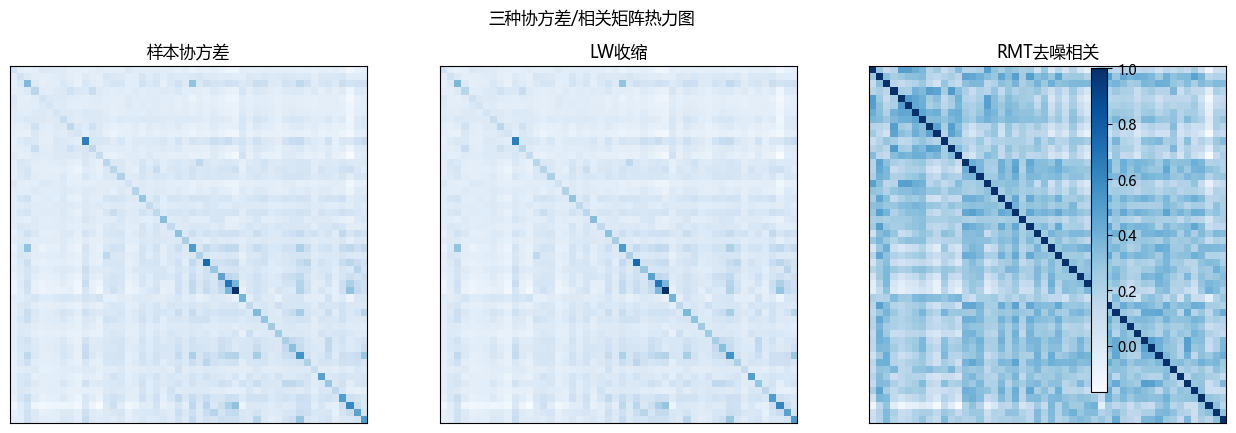

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
matrices = [('样本协方差', S.values), ('LW收缩', lw_self.values),
            ('RMT去噪相关', rm['corr'].values)]
for ax, (name, M) in zip(axes, matrices):
    im = ax.imshow(M, cmap='Blues')
    ax.set_title(name); ax.set_xticks([]); ax.set_yticks([])
fig.colorbar(im, ax=axes, fraction=0.02)
plt.suptitle('三种协方差/相关矩阵热力图', y=1.02)
plt.tight_layout(); plt.show()

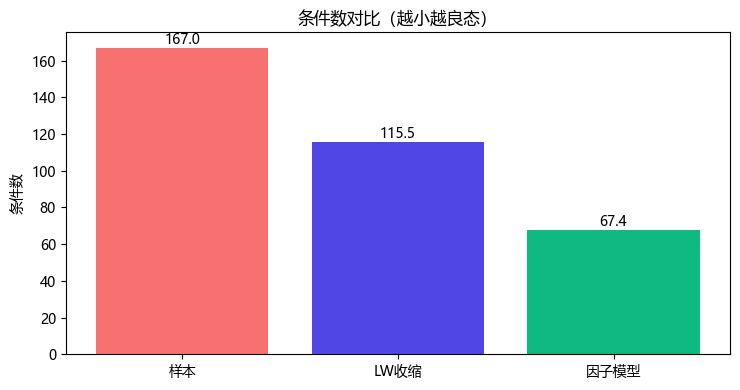

In [8]:
names = ['样本', 'LW收缩', '因子模型']
conds = [cond, np.linalg.cond(lw_self.values), np.linalg.cond(fc.values)]
fig, ax = plt.subplots(figsize=(7.5, 4))
bars = ax.bar(names, conds, color=['#f87171', '#4f46e5', '#10b981'])
for b, v in zip(bars, conds):
    ax.text(b.get_x()+b.get_width()/2, v, '%.1f' % v, ha='center', va='bottom')
ax.set_title('条件数对比（越小越良态）'); ax.set_ylabel('条件数')
plt.tight_layout(); plt.show()

## 八、结论与适用条件

- **样本协方差**仅在 $n/T$ 很小时可靠；高维下病态、优化结果不可信；
- **Ledoit-Wolf 收缩**无需先验、自动选强度，是最通用的「默认良态」估计，自实现与 sklearn 完全一致；
- **RMT 去噪**适合 $n/T$ 较大、存在少数主导因子的场景，能显式区分信号与噪声；
- **因子模型协方差**可解释、良态，精度依赖因子选择，是 Barra 体系的标准做法。
- 实务中常组合使用：因子模型 + 收缩处理残差，兼顾可解释性与良态。

## 九、面试要点

- **为什么不用样本协方差直接优化？** 高维下估计误差大、条件数高，优化器放大噪声得到角点解；
- **Ledoit-Wolf 收缩的目标和强度怎么定？** 向结构化目标（单位阵/对角/常数相关）收缩，强度由最小化 Frobenius 风险闭式解自动确定；
- **收缩的偏差-方差权衡？** 引入偏差但显著降低方差，整体 MSE 更小；
- **RMT 怎么去噪？** MP 分布给出噪声特征值边界，低于 $\lambda_+$ 的特征值替换为均值后重建；
- **因子模型协方差为什么良态？** 低秩结构 $\Sigma=B\Sigma_fB^\top+D$，待估参数大幅减少。

## 动手练习
1. 计算样本协方差条件数，再用 LW 收缩观察条件数下降；
2. 用 MP 公式确定 $\lambda_+$，统计信号/噪声特征值个数；
3. 对比样本、收缩、因子模型三种协方差的 Frobenius 距离。

---
下一节 M4.2 进入 GARCH/DCC 动态协方差。